# Esercizio 2) Caso con zeri multipli

Definire la funzione $f(x)=(x+1)^4 (x-3)$ e calcolarne la derivata. 
Poi:
- calcolare (a mano) gli zeri $x^*$ di $f$ e determinarne la molteplicità;
- plottare la funzione in $[-3, 3.5]$ e individuare graficamente gli zeri;
- provare il metodo di bisezione settando  $a, b$ opportunamente;
- provare il metodo Newton con $x_0=-2$ e $x_0=4$;
- confrontare le soluzioni ottenute e analizzare se si trovano tutti gli zeri con ciascun metodo;
- per il metodo di bisezione, analizzare la convergenza;
- per il metodo di Newton, confrontare i rapporti fra gli errori $e_k = |x^* - x_k|$ compiuti rispetto alle soluzioni esatte, stampando per ciascuna risoluzione

$$
\frac{e_{k+1}}{e_{k}}  \qquad e \qquad \frac{e_{k+1}}{e_{k}^2}
$$



In [2]:
import numpy as np
import matplotlib.pyplot as plt
eps = np.finfo(float).eps

#### Definizione del problema

In [3]:
def f(x):
    return (x + 1)**4 * (x - 3)



In [ ]:
x_star1 = 3
x_star2 = -1

Calcolo la derivata di $f(x) = (x+1)^4(x-3)$, cioè

$$ f'(x) = 4(x+1)^3(x-3) + 1(x+1)^4 = ... = (x+1)^3(5x-11)  .$$

In [15]:
def df(x):
    return (x + 1)**3 * (5*x - 11)

#### Visualizzazione

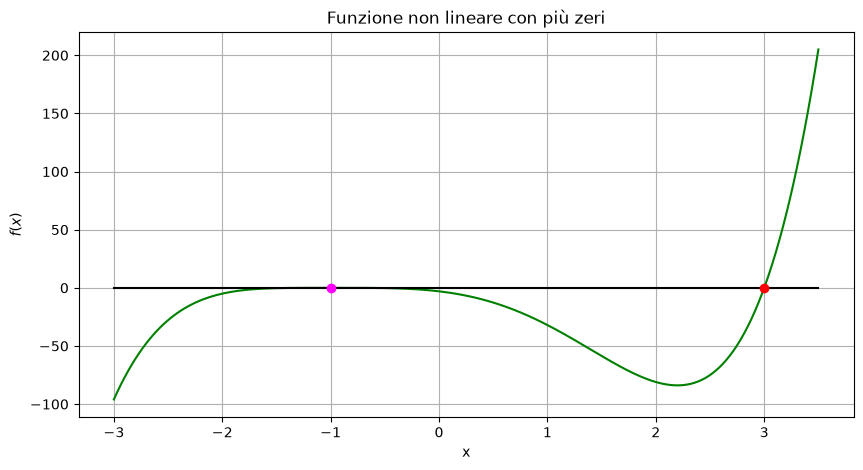

In [14]:
a = -3
b = 3.5

x = np.linspace(a, b, 200)
y = f(x)
yzeros = np.zeros_like(y)

plt.figure(figsize=(10, 5))
plt.plot(x,y, "-", color = 'green')
plt.plot(x,yzeros, "-", color = 'black')
plt.plot(x_star1, f(x_star1), 'o', color="red")
plt.plot(x_star2, f(x_star2), 'o', color="magenta")
plt.xlabel("x")
plt.ylabel(r"$f(x)$")
plt.title("Funzione non lineare con più zeri")
plt.grid(True)

#### Funzioni per la risoluzione iterativa

In [8]:
def bisezione(f, a, b, tol=1e-12, max_iter=100):

    fa = f(a)
    fb = f(b)
    iterati = []

    # Controllo degli estremi
    if fa * fb > 0:
        raise ValueError("La funzione deve cambiare segno in [a, b].")
    
    if fa == 0:
        return a, 0, iterati

    if fb == 0:
        return b, 0, iterati

    
    for k in range(1, max_iter + 1):

        # Punto medio e valore della funzione
        m = (a + b) / 2
        fm = f(m)

        # Memorizzo l'approssimazione corrente
        iterati.append(m)

        # Criterio di arresto
        if abs(b - a) / 2 <= tol + eps * min(abs(a), abs(b)) or fm == 0:
            print("Raggiunto il criterio di arresto.")
            return m, k, iterati

        # Seleziono il sottointervallo con cambio di segno, per la prossima iterazione
        if fa * fm < 0:
            b = m
        else:
            a = m
            fa = fm

    print("Raggiunto il numero massimo di iterazioni.")
    return m, k, iterati


def newton(f, df, x0, tol_x=1e-12, tol_f=1e-14, max_iter=100):

    x = x0    # x = float(x0)       
    iterati = [x]

    print(f"k = 0, x = {x:.15f}, f(x) = {f(x):.3e}")

    # Controllo del punto iniziale
    if abs(f(x)) <= tol_f:
        return x, 0, iterati
    
    for k in range(1, max_iter + 1):

        fx = f(x)
        dfx = df(x)

        # Controllo della derivata
        if dfx == 0:
            raise ValueError("Derivata nulla: impossibile proseguire.")

        # Nuova approssimazione
        x_nuovo = x - fx / dfx
        print(f"k = {k:2d}, x = {x_nuovo:.15f}, f(x) = {f(x_nuovo):.3e}")
        iterati.append(x_nuovo)

        # Incremento e residuo
        incremento = abs(x_nuovo - x)
        residuo = abs(f(x_nuovo))       # sarebbe: abs(f(x_nuovo) - f(x_star)) = abs(f(x_nuovo) - 0)

        # Criteri di arresto
        if incremento <= tol_x+ eps * min(abs(x_nuovo), abs(x)) or residuo <= tol_f:
            print("Raggiunto un criterio di arresto.")
            return x_nuovo, k, iterati

        # Aggiornamento per la prossima iterazione
        x = x_nuovo


    print("Raggiunto il numero massimo di iterazioni.")
    return x, max_iter, iterati



#### Risoluzione coi due metodi

In [16]:
print("METODO DI BISEZIONE")

a = -3
b = 3.5
x_bisez, n_iter_bisez, iterati_bisez = bisezione(f, a, b)

print("Zero approssimato:", x_bisez)
print("Numero di iterazioni:", n_iter_bisez)

METODO DI BISEZIONE
Raggiunto il criterio di arresto.
Zero approssimato: 3.0000000000006253
Numero di iterazioni: 43


In [21]:
print("METODO DI NEWTON - 1")

x0 = 4 
x_newton1, n_iter_newton1, iterati_newton1 = newton(f, df, x0)

print("Zero approssimato:", x_newton1)
print("Numero di iterazioni:", n_iter_newton1)

METODO DI NEWTON - 1
k = 0, x = 4.000000000000000, f(x) = 6.250e+02
k =  1, x = 3.444444444444445, f(x) = 1.734e+02
k =  2, x = 3.126984126984127, f(x) = 3.684e+01
k =  3, x = 3.013916068710589, f(x) = 3.612e+00
k =  4, x = 3.000190345885334, f(x) = 4.874e-02
k =  5, x = 3.000000036222938, f(x) = 9.273e-06
k =  6, x = 3.000000000000001, f(x) = 3.411e-13
k =  7, x = 3.000000000000000, f(x) = 0.000e+00
Raggiunto un criterio di arresto.
Zero approssimato: 3.0
Numero di iterazioni: 7


In [30]:
print("METODO DI NEWTON - 2")

x0 = -2 
# da finire

METODO DI NEWTON - 2


#### Confronto

In [31]:
iterati_bisez = np.array(iterati_bisez)
iterati_newton1 = np.array(iterati_newton1)
# iterati_newton2 = np.array(iterati_newton2)

In [23]:
print(x_star1)
print(x_star2)

3
-1


In [43]:
print("BISEZIONE")
print("k \t  errore   \t intervallo")
print("---------------------------------------")
print( f"0 \t - \t \t {np.abs(b-a):.3e} " )

for k in range(1, n_iter_bisez+1): 
    errore_k = np.abs(x_star1 - iterati_bisez[k-1])
    intervallo = np.abs(b-a)/(2**k)
    print( f"{k} \t {errore_k:.3e}  \t {intervallo:.3e} " )

BISEZIONE
k 	  errore   	 intervallo
---------------------------------------
0 	 - 	 	 6.500e+00 
1 	 2.750e+00  	 3.250e+00 
2 	 1.125e+00  	 1.625e+00 
3 	 3.125e-01  	 8.125e-01 
4 	 9.375e-02  	 4.062e-01 
5 	 1.094e-01  	 2.031e-01 
6 	 7.812e-03  	 1.016e-01 
7 	 4.297e-02  	 5.078e-02 
8 	 1.758e-02  	 2.539e-02 
9 	 4.883e-03  	 1.270e-02 
10 	 1.465e-03  	 6.348e-03 
11 	 1.709e-03  	 3.174e-03 
12 	 1.221e-04  	 1.587e-03 
13 	 6.714e-04  	 7.935e-04 
14 	 2.747e-04  	 3.967e-04 
15 	 7.629e-05  	 1.984e-04 
16 	 2.289e-05  	 9.918e-05 
17 	 2.670e-05  	 4.959e-05 
18 	 1.907e-06  	 2.480e-05 
19 	 1.049e-05  	 1.240e-05 
20 	 4.292e-06  	 6.199e-06 
21 	 1.192e-06  	 3.099e-06 
22 	 3.576e-07  	 1.550e-06 
23 	 4.172e-07  	 7.749e-07 
24 	 2.980e-08  	 3.874e-07 
25 	 1.639e-07  	 1.937e-07 
26 	 6.706e-08  	 9.686e-08 
27 	 1.863e-08  	 4.843e-08 
28 	 5.588e-09  	 2.421e-08 
29 	 6.519e-09  	 1.211e-08 
30 	 4.657e-10  	 6.054e-09 
31 	 2.561e-09  	 3.027e-09 
32 	 1.048e-

In [ ]:
print("NEWTON")
print("k \t  errore   \t rapp lineare  \t rapp  quadratico")
print("----------------------------------------------------")
for k in range(0, n_iter_newton1): 
    errore_k = np.abs(x_star1 - iterati_newton1[k])
    errore_kp1 = np.abs(x_star1 - iterati_newton1[k+1])
    print( f"{k} \t {errore_k:.3e}  \t {errore_kp1/errore_k:.3e}  \t {errore_kp1/errore_k**2:.3e}" )

k 	  errore   	 rapp lineare  	 rapp  quadratico
----------------------------------------------------
0 	 1.000e+00  	 4.444e-01  	 4.444e-01
1 	 4.444e-01  	 2.857e-01  	 6.429e-01
2 	 1.270e-01  	 1.096e-01  	 8.630e-01
3 	 1.392e-02  	 1.368e-02  	 9.829e-01
4 	 1.903e-04  	 1.903e-04  	 9.998e-01
5 	 3.622e-08  	 3.678e-08  	 1.015e+00
6 	 1.332e-15  	 0.000e+00  	 0.000e+00


In [ ]:
# da finire